# AI5707 — Pattern Recognition and Machine Learning
## Assignment 7: GMM Models and Pattern Recognition

**Team 16 — assigned digits: 3, 5, and 9**

This notebook answers the MNIST-related questions in Assignment 7:
- Build one GMM model for each assigned digit using **training data only**.
- Classify the test images and record the results.
- Use the trained models and class boundaries to discuss why digits are confused.

**The Assignment 6 synthetic-data section has been removed**, as requested.

## 1. GMM theory and classification

A Gaussian Mixture Model represents a probability distribution as a weighted sum of Gaussian components:

$$
p(\mathbf{x})=\sum_{j=1}^{K}\pi_j
\mathcal{N}(\mathbf{x};\boldsymbol{\mu}_j,\boldsymbol{\Sigma}_j)
$$

Here, $K$ is the number of Gaussian components, $\pi_j$ is the mixing weight, $\boldsymbol{\mu}_j$ is the mean, and $\boldsymbol{\Sigma}_j$ is the covariance matrix. The weights satisfy $\pi_j\geq 0$ and $\sum_{j=1}^{K}\pi_j=1$.

For class $c$, the model estimates $p(\mathbf{x}\mid C_c)$. We predict the class with the highest class-conditional log-likelihood:

$$
\hat{y}=\arg\max_{c\in\{3,5,9\}}\log p(\mathbf{x}\mid C_c).
$$

The GMM parameters are fitted using Expectation-Maximization (EM). The E-step estimates component responsibilities; the M-step updates weights, means, and covariances.

## 2. Dataset and modelling plan

Each MNIST image is a $28\times28$ grayscale image, flattened into **784 normalized pixel features**. The folder structure should be:

```text
Lab 7/
├── TEAM_16/
│   ├── train/3, train/5, train/9
│   ├── dev/3,   dev/5,   dev/9
│   └── test/3,  test/5,  test/9
├── AI5707_Assignment_7.pdf
└── main.ipynb
```

We use PCA to reduce dimensionality from 784 features to 40. PCA is fitted on the training images only; development and test images are transformed using that same fitted PCA. GMM component count is selected on the development set, and the test set is used for final evaluation only.

## 3. Import libraries and set paths
Run this cell first. Keep `main.ipynb` in your `Lab 7` folder.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.mixture import GaussianMixture

DIGITS = [3, 5, 9]
SEED = 42
PCA_COMPONENTS = 40
COMPONENT_COUNTS = [1, 2, 4, 6, 8]

DATA_PATH = Path(".")       # current folder should be Lab 7
OUT = Path("assignment7_outputs")
OUT.mkdir(exist_ok=True)

print("Current folder:", Path.cwd())
print("Dataset folder:", (DATA_PATH / "TEAM_16").resolve())

Current folder: d:\Storage\OneDrive\Documents\SNU Chennai\PRML Lab\Lab 7
Dataset folder: D:\Storage\OneDrive\Documents\SNU Chennai\PRML Lab\Lab 7\TEAM_16


## 4. Locate the dataset and load images
This cell checks for the expected folders and reads the PNG images. Every image is converted to grayscale, flattened to 784 values, and normalized to the range 0–1.

In [2]:
def find_team_root(path: Path) -> Path:
    """Find TEAM_16 directly inside the given path or one of its subfolders."""
    if (path / "TEAM_16").is_dir():
        return path / "TEAM_16"
    if path.name == "TEAM_16" and path.is_dir():
        return path
    for candidate in path.rglob("TEAM_16"):
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError(
        f"Could not find TEAM_16 under {path}. Expected train/dev/test folders."
    )


def load_image_split(root: Path, split: str):
    """Return flattened normalized images, labels, and original image paths."""
    features, labels, filenames = [], [], []

    for digit in DIGITS:
        folder = root / split / str(digit)
        if not folder.is_dir():
            raise FileNotFoundError(f"Missing folder: {folder}")

        image_paths = sorted(folder.glob("*.png"))
        if not image_paths:
            raise FileNotFoundError(f"No PNG images found in {folder}")

        for image_path in image_paths:
            with Image.open(image_path) as image:
                image_array = np.asarray(image.convert("L"), dtype=np.float32).reshape(-1) / 255.0
            if image_array.size != 784:
                raise ValueError(
                    f"{image_path} has {image_array.size} pixels, expected 784 (28x28)."
                )
            features.append(image_array)
            labels.append(digit)
            filenames.append(str(image_path))

    return np.stack(features), np.asarray(labels, dtype=int), filenames

### Load train, development, and test splits
Only the training split will be used to fit PCA and the GMM models. The development split selects the number of components. The test split is held out for final reporting.

In [3]:
team_root = find_team_root(DATA_PATH)

X_train, y_train, train_paths = load_image_split(team_root, "train")
X_dev, y_dev, dev_paths = load_image_split(team_root, "dev")
X_test, y_test, test_paths = load_image_split(team_root, "test")

print("Original image features:", X_train.shape[1])
print("Train images:", len(y_train))
print("Development images:", len(y_dev))
print("Test images:", len(y_test))

for split_name, labels in [
    ("Train", y_train), ("Development", y_dev), ("Test", y_test)
]:
    print(split_name, "class counts:",
          {str(d): int(np.sum(labels == d)) for d in DIGITS})

Original image features: 784
Train images: 14030
Development images: 3471
Test images: 2911
Train class counts: {'3': 4886, '5': 4368, '9': 4776}
Development class counts: {'3': 1245, '5': 1053, '9': 1173}
Test class counts: {'3': 1010, '5': 892, '9': 1009}


## 5. Dimensionality reduction using PCA

PCA transforms the original feature vector $\mathbf{x}\in\mathbb{R}^{784}$ into a lower-dimensional vector $\mathbf{z}\in\mathbb{R}^{40}$. It keeps directions with high variance to reduce the computational cost of fitting GMMs.

The PCA transformation is learned **only from the training data**:

$$
\mathbf{z}=\mathbf{W}^{T}(\mathbf{x}-\boldsymbol{\mu}).
$$

Here, $\mathbf{W}$ contains the selected principal directions and $\boldsymbol{\mu}$ is the training-data mean.

In [4]:
n_pca = min(PCA_COMPONENTS, X_train.shape[0] - 1, X_train.shape[1])
pca = PCA(n_components=n_pca, svd_solver="randomized", random_state=SEED)

Z_train = pca.fit_transform(X_train)  # fit PCA on training images only
Z_dev = pca.transform(X_dev)          # transform only
Z_test = pca.transform(X_test)        # transform only

print(f"PCA dimensions: {X_train.shape[1]} -> {n_pca}")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.2%}")

PCA dimensions: 784 -> 40
Variance retained: 79.73%


## 6. Fit one GMM for each digit

For each candidate $K$, we fit a separate GMM for digit 3, digit 5, and digit 9. The models use diagonal covariance matrices, which require fewer parameters than full covariance matrices and are more practical in the reduced feature space.

The class prediction uses the log-likelihood:

$$
s_c(\mathbf{z})=\log p(\mathbf{z}\mid C_c),\qquad
\hat{y}=\arg\max_{c\in\{3,5,9\}}s_c(\mathbf{z}).
$$

In [5]:
def fit_gmm_models(features, labels, n_components):
    """Fit a separate diagonal-covariance GMM for each assigned digit."""
    models = {}

    for digit in DIGITS:
        model = GaussianMixture(
            n_components=n_components,
            covariance_type="diag",
            reg_covar=1e-5,
            n_init=3,
            max_iter=300,
            random_state=SEED,
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            model.fit(features[labels == digit])
        models[digit] = model

    return models


def predict_by_log_likelihood(models, features):
    """Predict the digit with the largest class-conditional log-likelihood."""
    scores = np.column_stack([
        models[digit].score_samples(features) for digit in DIGITS
    ])
    predictions = np.asarray(DIGITS)[np.argmax(scores, axis=1)]
    return predictions, scores

## 7. Select the number of components using the development set

We compare $K\in\{1,2,4,6,8\}$. For each value, GMMs are trained on the training set and evaluated on the development set. The $K$ with the highest development accuracy is selected.

**Why use a development set?** It allows model selection without using test labels. The test set remains independent for the final evaluation.

In [6]:
component_results = []
models_by_k = {}

for k in COMPONENT_COUNTS:
    models = fit_gmm_models(Z_train, y_train, n_components=k)
    dev_predictions, _ = predict_by_log_likelihood(models, Z_dev)
    dev_accuracy = accuracy_score(y_dev, dev_predictions)

    component_results.append({
        "components_per_digit": k,
        "development_accuracy": float(dev_accuracy),
    })
    models_by_k[k] = models
    print(f"K={k}: development accuracy = {dev_accuracy:.4%}")

best_k = max(
    component_results,
    key=lambda row: row["development_accuracy"]
)["components_per_digit"]

best_models = models_by_k[best_k]
print(f"\nSelected K={best_k} per digit based on development accuracy.")

K=1: development accuracy = 92.5094%
K=2: development accuracy = 94.2380%
K=4: development accuracy = 95.3904%
K=6: development accuracy = 95.3039%
K=8: development accuracy = 95.7073%

Selected K=8 per digit based on development accuracy.


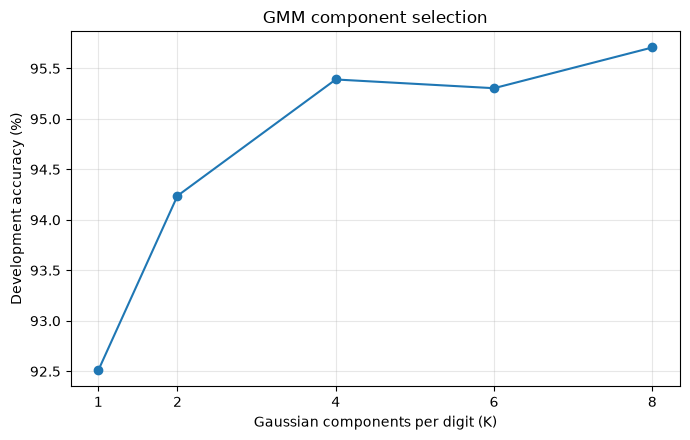

In [7]:
ks = [row["components_per_digit"] for row in component_results]
dev_accuracies = [100 * row["development_accuracy"] for row in component_results]

plt.figure(figsize=(7, 4.5))
plt.plot(ks, dev_accuracies, marker="o")
plt.xlabel("Gaussian components per digit (K)")
plt.ylabel("Development accuracy (%)")
plt.title("GMM component selection")
plt.xticks(ks)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Test classification and results

Now classify the held-out test images using the selected GMMs. The confusion matrix uses **rows = true digit** and **columns = predicted digit**, ordered as $[3,5,9]$.

Accuracy is

$$
\text{Accuracy}=\frac{\text{number of correct predictions}}
{\text{number of test images}}.
$$

For each class,

$$
\text{Precision}=\frac{TP}{TP+FP},\qquad
\text{Recall}=\frac{TP}{TP+FN},
$$

$$
F_1=2\frac{\text{Precision}\times\text{Recall}}
{\text{Precision}+\text{Recall}}.
$$

In [8]:
test_predictions, test_log_likelihoods = predict_by_log_likelihood(
    best_models, Z_test
)

test_accuracy = accuracy_score(y_test, test_predictions)
cm = confusion_matrix(y_test, test_predictions, labels=DIGITS)

print(f"Selected components per digit: {best_k}")
print(f"Final test accuracy: {test_accuracy:.4%}")
print("\nConfusion matrix (rows=true, columns=predicted; order 3, 5, 9):")
print(cm)
print("\nClassification report:")
print(classification_report(
    y_test, test_predictions, labels=DIGITS, zero_division=0
))

Selected components per digit: 8
Final test accuracy: 96.5648%

Confusion matrix (rows=true, columns=predicted; order 3, 5, 9):
[[974  25  11]
 [ 26 860   6]
 [ 18  14 977]]

Classification report:
              precision    recall  f1-score   support

           3       0.96      0.96      0.96      1010
           5       0.96      0.96      0.96       892
           9       0.98      0.97      0.98      1009

    accuracy                           0.97      2911
   macro avg       0.97      0.97      0.97      2911
weighted avg       0.97      0.97      0.97      2911



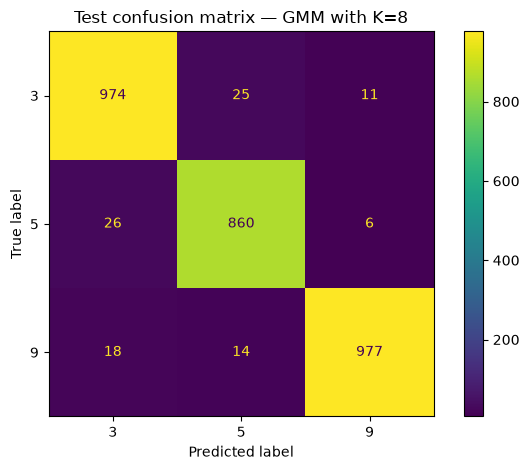

In [9]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=DIGITS)
disp.plot(values_format="d")
plt.title(f"Test confusion matrix — GMM with K={best_k}")
plt.tight_layout()
plt.show()

## 9. Explain digit confusions using the GMM models

The assignment asks you to explain confusion primarily by looking at the **boundaries between classes**. A GMM assigns each image a likelihood under each digit model. The predicted class is the one with the highest score. A mistake happens when a test image receives a higher likelihood from the wrong class model.

Handwritten digits can overlap in feature space because of different writing styles, similar curves, loops, or incomplete strokes. Use the confusion matrix to identify the largest off-diagonal entry, then inspect the corresponding examples and their model scores. Do not claim a particular visual cause without checking the actual misclassified images.

In [10]:
# Collect misclassified test images and likelihood evidence.
misclassified = []

for i, (true_digit, predicted_digit) in enumerate(zip(y_test, test_predictions)):
    if true_digit != predicted_digit:
        true_score = float(test_log_likelihoods[i, DIGITS.index(int(true_digit))])
        predicted_score = float(test_log_likelihoods[i, DIGITS.index(int(predicted_digit))])
        misclassified.append({
            "test_index": int(i),
            "image_path": test_paths[i],
            "true_digit": int(true_digit),
            "predicted_digit": int(predicted_digit),
            "true_class_log_likelihood": true_score,
            "predicted_class_log_likelihood": predicted_score,
        })

with open(OUT / "mnist_misclassified_examples.json", "w", encoding="utf-8") as f:
    json.dump(misclassified, f, indent=2)

print("Number of misclassified test images:", len(misclassified))
print("Misclassification file:", OUT / "mnist_misclassified_examples.json")

# Summarize which true/predicted pairs are most often confused.
pair_counts = {}
for item in misclassified:
    pair = (item["true_digit"], item["predicted_digit"])
    pair_counts[pair] = pair_counts.get(pair, 0) + 1

print("True digit -> predicted digit counts:")
for pair, count in sorted(pair_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"{pair[0]} -> {pair[1]}: {count}")

Number of misclassified test images: 100
Misclassification file: assignment7_outputs\mnist_misclassified_examples.json
True digit -> predicted digit counts:
5 -> 3: 26
3 -> 5: 25
9 -> 3: 18
9 -> 5: 14
3 -> 9: 11
5 -> 9: 6


### Inspect misclassified images

The next cell displays up to 12 misclassified images with their true and predicted labels. Use these images along with the confusion matrix to write the explanation of the most common confusion.

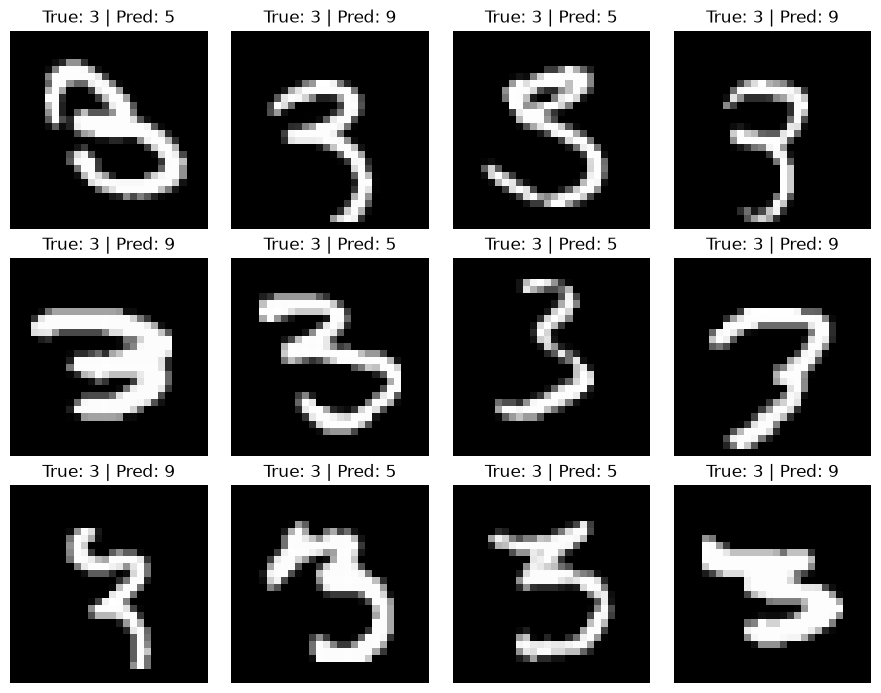

In [11]:
if misclassified:
    n_show = min(12, len(misclassified))
    fig, axes = plt.subplots(3, 4, figsize=(9, 7))
    axes = axes.ravel()

    for ax in axes:
        ax.axis("off")

    for ax, item in zip(axes, misclassified[:n_show]):
        with Image.open(item["image_path"]) as im:
            ax.imshow(im.convert("L"), cmap="gray")
        ax.set_title(
            f"True: {item['true_digit']} | Pred: {item['predicted_digit']}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images to display.")

## 10. Save results and assignment answers

This cell saves the main numerical results so they can be used in the report. Use the values from **your run** when writing the submission.

In [12]:
results = {
    "team": 16,
    "digits": DIGITS,
    "original_features": int(X_train.shape[1]),
    "pca_components": int(n_pca),
    "pca_variance_retained": float(pca.explained_variance_ratio_.sum()),
    "train_counts": {str(d): int(np.sum(y_train == d)) for d in DIGITS},
    "development_counts": {str(d): int(np.sum(y_dev == d)) for d in DIGITS},
    "test_counts": {str(d): int(np.sum(y_test == d)) for d in DIGITS},
    "component_selection": component_results,
    "selected_components_per_digit": int(best_k),
    "test_accuracy": float(test_accuracy),
    "confusion_matrix_labels": DIGITS,
    "confusion_matrix_rows_true_columns_predicted": cm.tolist(),
    "classification_report": classification_report(
        y_test, test_predictions, labels=DIGITS,
        output_dict=True, zero_division=0
    ),
    "misclassified_count": len(misclassified),
    "misclassified_examples_file": "mnist_misclassified_examples.json",
}

with open(OUT / "assignment7_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print("Saved:", OUT / "assignment7_results.json")
print("Saved:", OUT / "mnist_misclassified_examples.json")

Saved: assignment7_outputs\assignment7_results.json
Saved: assignment7_outputs\mnist_misclassified_examples.json


## 11. Written answers to the assignment questions

### Question 2 — Build a GMM for each assigned digit
A separate GMM is trained for each of digits 3, 5, and 9 using only the training split. PCA is fitted on the training images and then applied to the development and test images. The number of GMM components is selected by comparing development accuracy.

### Question 3 — Classify test data and record results
Report the selected value of $K$, final test accuracy, classification report, and confusion matrix printed in Section 8. These are produced from the held-out test split.

### Question 4 — Explain confusions
Use the off-diagonal cells of the test confusion matrix to find which digit pairs are confused most often. Section 9 saves the corresponding image paths, class log-likelihoods, and displays examples. Explain the mistakes in terms of overlap between the learned class-conditional distributions and the boundary where two classes have similar likelihood.

**Important:** The PDF asks for the MNIST results and the explanation of class-boundary confusions. The synthetic-data output from Assignment 6 is intentionally omitted from this notebook, as requested.